# Phase 2 · Full-scene inference

Classifies every pixel of the Sentinel-2 scene with the model selected in `02_phase2_tuning.ipynb` and produces the deliverables of section 3.4 of the brief:

- **Model**: the configuration with the best cross-validated macro-F1, refit on every labelled pixel (training + holdout). The holdout already gave its independent estimate; the map uses all the reference data. It is registered in MLflow as `sentinel2-land-cover` with the alias `production`.
- **Raster**: single-band `uint8` GeoTIFF on the source grid (same CRS, transform and size), with the class codes of Figure 2, `255` as NoData (0 is the code of the NO_DATA class) and an embedded colour table. Uploaded to `s3://sentinel2/predictions/`.
- **Areas**: pixels and area per class in hectares and km², stored in `training.class_areas`.
- **Map**: thematic map with the Figure 2 colours next to a true-colour composite.

Run it after `02_phase2_tuning.ipynb`. Outputs go to `outputs/inference/`; the GeoTIFF also goes to `data/predictions/` (git-ignored).

In [1]:
import io
import json
import os
import tempfile
import time
from pathlib import Path

import boto3
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import rasterio
from joblib import Parallel, delayed
import skops.io as sio
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from mlflow import MlflowClient
from mlflow.models import infer_signature
from sklearn.base import clone
from sqlalchemy import URL, create_engine, text

# The selected pipeline may use the feature transformer of this folder.
os.environ["PYTHONPATH"] = os.pathsep.join(filter(None, [str(Path.cwd()), os.environ.get("PYTHONPATH")]))
import sentinel2_features  # noqa: F401  (needed to rebuild pipelines that use it)

DATASET = "T18NWL_20260810T152649"
BANDS = [band.strip() for band in os.environ["BAND_NAMES"].split(",")]
MODEL_NAME, MODEL_ALIAS = os.environ["MODEL_NAME"], os.environ["MODEL_ALIAS"]
DATA_BUCKET = os.environ["DATA_BUCKET"]
REQUIRED_MODELS = {"dummy", "logistic_regression", "naive_bayes", "decision_tree", "random_forest",
                   "gradient_boosting", "knn", "svm", "neural_network"}
NODATA_DN = 0        # band value of missing data in Sentinel-2 L2A (the files declare none)
NODATA_CODE = 255    # output code of pixels without data; 0 is a class code (NO_DATA) in Figure 2
CHUNK = 250_000      # pixels predicted per task
N_JOBS = 14           # parallel prediction tasks; the container has 10 cores
OUTPUTS = Path("outputs/inference")
OUTPUTS.mkdir(parents=True, exist_ok=True)
RASTERS = Path("/home/jovyan/data/predictions")  # ./data/predictions on the host
RASTERS.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = {
    0: "No data", 1: "Saturated or defective", 2: "Dark area pixels", 3: "Cloud shadows",
    4: "Vegetation", 5: "Not vegetated", 6: "Water", 7: "Unclassified",
    8: "Cloud medium probability", 9: "Cloud high probability", 10: "Thin cirrus", 11: "Snow",
}
# Colours of Figure 2 of the brief.
CLASS_COLORS = {
    0: "#000000", 1: "#ff0000", 2: "#404040", 3: "#7b4a1e", 4: "#00ee00", 5: "#ffff00",
    6: "#1c3ca8", 7: "#8c8c8c", 8: "#c8c8c8", 9: "#f2f2ee", 10: "#5ee0f5", 11: "#ff8cf0",
}


def log(message):
    print(f"[{time.strftime('%H:%M:%S')}] {message}", flush=True)

## 1. Selected model

The model and its hyper-parameters come from the phase 2 search; nothing is chosen here. `clone` keeps the selected configuration and drops the fitted state.

In [2]:
phase2 = json.loads(Path("outputs/phase2/metrics.json").read_text())
missing = REQUIRED_MODELS - {m["key"] for m in phase2["models"]}
assert not missing, f"outputs/phase2 is incomplete, re-run 02_phase2_tuning.ipynb: {missing}"
selected = next(m for m in phase2["models"] if m["key"] == phase2["selected"])
tuned = mlflow.sklearn.load_model(f"runs:/{selected['mlflow_run_id']}/model")
final_model = clone(tuned)
log(f"selected {selected['model']} (cross-validated macro-F1 {selected['cv_f1_macro_mean']:.4f}; "
    f"holdout OA {selected['test_overall_accuracy']:.4f}, kappa {selected['test_kappa']:.4f}, "
    f"macro-F1 {selected['test_f1_macro']:.4f})")
final_model

[21:18:05] selected Support Vector Machine (cross-validated macro-F1 0.7307; holdout OA 0.9356, kappa 0.8492, macro-F1 0.6848)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('scale', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,log,True
,indices,False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1000
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",500


## 2. Refit on every labelled pixel

In [3]:
s3 = boto3.client("s3", endpoint_url=os.environ["MLFLOW_S3_ENDPOINT_URL"])
body = s3.get_object(Bucket=DATA_BUCKET, Key=f"tsv/{DATASET}.tsv")["Body"].read()
samples = pd.read_csv(io.BytesIO(body), sep="\t", float_precision="round_trip")
assert list(samples.columns) == ["Latitude", "Longitude", *BANDS, "Class"], samples.columns
X_all, y_all = samples[BANDS].astype("float64"), samples["Class"]

started = time.time()
final_model.fit(X_all, y_all)
fit_seconds = time.time() - started
log(f"refit on {len(y_all):,} pixels in {fit_seconds / 60:.1f} min; classes {final_model.classes_.tolist()}")

[22:29:06] refit on 583,835 pixels in 71.0 min; classes [2, 3, 4, 5, 6, 7, 8, 9, 10]


## 3. Register the production model

The run carries the holdout metrics of the selected configuration (fit on the training split only), so the dashboard shows the independent estimate, and the parameters of the search that chose it.

In [4]:
def trusted_types(model):
    # The model was built in this project; trust exactly the types skops reports as unknown.
    return sio.get_untrusted_types(data=sio.dumps(model))


mlflow.set_experiment(os.environ["MLFLOW_EXPERIMENT_NAME"])
with mlflow.start_run(run_name=f"phase2-final-{selected['key']}") as run:
    mlflow.log_params({
        "phase": 2, "model": selected["model"], "dataset": DATASET, "bands": ",".join(BANDS),
        "fit_on": f"all labelled pixels ({len(y_all)})", "selected_from_run": selected["mlflow_run_id"],
        "selection": "best cross-validated macro-F1 (10 grouped validations)",
        **{k: str(v) for k, v in final_model.get_params().items() if k.startswith(("model__", "features__"))},
    })
    mlflow.log_metrics({
        **{k: v for k, v in selected.items() if k.startswith(("cv_", "test_"))},
        "fit_seconds": fit_seconds,
    })
    model_info = mlflow.sklearn.log_model(
        final_model, name="model", registered_model_name=MODEL_NAME,
        signature=infer_signature(X_all.head(100), final_model.predict(X_all.head(100))),
        input_example=X_all.head(3), skops_trusted_types=trusted_types(final_model),
        code_paths=["sentinel2_features.py"],
    )
    final_run_id = run.info.run_id

client = MlflowClient()
version = model_info.registered_model_version
client.set_registered_model_alias(MODEL_NAME, MODEL_ALIAS, version)
log(f"registered {MODEL_NAME} version {version} with alias {MODEL_ALIAS} (run {final_run_id})")

Successfully registered model 'sentinel2-land-cover'.
2026/11/26 22:29:09 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: sentinel2-land-cover, version 1
Created version '1' of model 'sentinel2-land-cover'.


🏃 View run phase2-final-svm at: http://mlflow:5000/#/experiments/1/runs/30916545c37e4440b33c84e190ebf243
🧪 View experiment at: http://mlflow:5000/#/experiments/1
[22:29:10] registered sentinel2-land-cover version 1 with alias production (run 30916545c37e4440b33c84e190ebf243)


🏃 View run phase2-final-svm at: http://mlflow:5000/#/experiments/2/runs/c158cc2ca3b14628ad520bf17246a4ca
🧪 View experiment at: http://mlflow:5000/#/experiments/2
[07:56:45] registered sentinel2-land-cover version 1 with alias production (run c158cc2ca3b14628ad520bf17246a4ca)


## 4. Read the scene

The ten bands are checked to share CRS, transform, size and the 20 m resolution before they are stacked. A pixel is NoData when any band is 0.

In [5]:
band_dir = Path(tempfile.mkdtemp())
stack, grid = [], None
for band in BANDS:
    path = band_dir / f"{band}.jp2"
    s3.download_file(DATA_BUCKET, f"bands/{DATASET}_{band}_20m.jp2", str(path))
    with rasterio.open(path) as raster:
        this_grid = {"crs": raster.crs, "transform": raster.transform, "width": raster.width, "height": raster.height}
        grid = grid or this_grid
        assert this_grid == grid, f"{band} is not on the grid of {BANDS[0]}"
        assert raster.res == (20.0, 20.0), f"{band} resolution {raster.res}"
        stack.append(raster.read(1))
stack = np.stack(stack)                                  # (bands, rows, cols), uint16 digital numbers
valid = (stack != NODATA_DN).all(axis=0)
pixel_area_m2 = abs(grid["transform"].a * grid["transform"].e)
assert pixel_area_m2 == 400.0
log(f"{grid['width']} x {grid['height']} pixels, {grid['crs']}, origin "
    f"({grid['transform'].c:.0f}, {grid['transform'].f:.0f}); NoData pixels: {(~valid).sum():,}")

[22:29:12] 5490 x 5490 pixels, EPSG:32618, origin (499980, 600000); NoData pixels: 1


## 5. Predict every valid pixel

In [6]:
flat = stack.reshape(len(BANDS), -1)
valid_index = np.flatnonzero(valid.ravel())
classes = np.full(flat.shape[1], NODATA_CODE, dtype=np.uint8)


def predict_chunk(model, values):
    return model.predict(pd.DataFrame(values.astype("float64"), columns=BANDS)).astype(np.uint8)


chunks = [valid_index[start:start + CHUNK] for start in range(0, len(valid_index), CHUNK)]
started = time.time()
predicted = Parallel(n_jobs=N_JOBS)(delayed(predict_chunk)(final_model, flat[:, index].T) for index in chunks)
for index, values in zip(chunks, predicted):
    classes[index] = values
del predicted
predict_seconds = time.time() - started
prediction = classes.reshape(grid["height"], grid["width"])
log(f"predicted {len(valid_index):,} pixels in {predict_seconds / 60:.1f} min")

[00:52:10] predicted 30,140,099 pixels in 143.0 min


## 6. Export the GeoTIFF

Same CRS, transform and size as the bands, so the map overlays the source imagery pixel by pixel. The colour table makes QGIS show the Figure 2 colours without extra styling.

In [7]:
raster_name = f"{DATASET}_landcover_{selected['key']}_v{version}.tif"
raster_path = RASTERS / raster_name
profile = {
    "driver": "GTiff", "dtype": "uint8", "count": 1, "nodata": NODATA_CODE,
    "crs": grid["crs"], "transform": grid["transform"], "width": grid["width"], "height": grid["height"],
    "compress": "deflate", "tiled": True, "blockxsize": 512, "blockysize": 512,
}
with rasterio.open(raster_path, "w", **profile) as out:
    out.write(prediction, 1)
    out.write_colormap(1, {code: tuple(int(color[i:i + 2], 16) for i in (1, 3, 5)) + (255,)
                           for code, color in CLASS_COLORS.items()})
    out.set_band_description(1, "land-cover class (Figure 2 codes)")
    out.update_tags(dataset=DATASET, model=selected["model"], model_name=MODEL_NAME,
                    model_version=str(version), mlflow_run=final_run_id, nodata_code=str(NODATA_CODE),
                    classes=json.dumps({str(k): v for k, v in CLASS_NAMES.items()}))

# Re-open and check the grid and the codes.
with rasterio.open(raster_path) as check:
    assert (check.crs, check.transform, check.width, check.height) == \
        (grid["crs"], grid["transform"], grid["width"], grid["height"]), "grid differs from the bands"
    written = check.read(1)
    assert np.array_equal(written, prediction)
    codes = sorted(np.unique(written).tolist())
assert set(codes) <= set(final_model.classes_.tolist()) | {NODATA_CODE}, codes

prediction_key = f"predictions/{raster_name}"
s3.upload_file(str(raster_path), DATA_BUCKET, prediction_key)
log(f"wrote {raster_path} ({raster_path.stat().st_size / 1e6:.1f} MB), codes {codes}; "
    f"uploaded to s3://{DATA_BUCKET}/{prediction_key}")

[00:52:11] wrote /home/jovyan/data/predictions/T18NWL_20260810T152649_landcover_svm_v1.tif (3.3 MB), codes [2, 3, 4, 5, 6, 7, 8, 9, 10, 255]; uploaded to s3://sentinel2/predictions/T18NWL_20260810T152649_landcover_svm_v1.tif


## 7. Area per class

The CRS is UTM (metres), so every pixel covers 20 m × 20 m = 400 m² = 0.04 ha.

In [8]:
counts = np.bincount(prediction.ravel(), minlength=256)
mapped = int(valid.sum())
areas = pd.DataFrame([
    {"class_id": code, "name": CLASS_NAMES[code], "pixels": int(counts[code]),
     "area_ha": counts[code] * pixel_area_m2 / 1e4, "area_km2": counts[code] * pixel_area_m2 / 1e6,
     "share_pct": 100 * counts[code] / mapped}
    for code in CLASS_NAMES if counts[code] > 0
])
assert areas["pixels"].sum() == mapped, "class areas do not add up to the mapped area"
nodata_pixels = int(counts[NODATA_CODE])
areas.round(4).to_csv(OUTPUTS / "class_areas.csv", index=False)

with create_engine(URL.create(
    "postgresql+psycopg2", username=os.environ["TRAIN_DB_USER"], password=os.environ["TRAIN_DB_PASSWORD"],
    host=os.environ["TRAIN_DB_HOST"], port=int(os.environ["TRAIN_DB_PORT"]), database=os.environ["TRAIN_DB_NAME"],
)).begin() as connection:
    connection.execute(text("DELETE FROM training.class_areas WHERE prediction = :p"), {"p": prediction_key})
    connection.execute(
        text("INSERT INTO training.class_areas (prediction, class_id, pixel_count, area_ha, model_name, model_version) "
             "VALUES (:prediction, :class_id, :pixel_count, :area_ha, :model_name, :model_version)"),
        [{"prediction": prediction_key, "class_id": int(r.class_id), "pixel_count": int(r.pixels),
          "area_ha": float(r.area_ha), "model_name": MODEL_NAME, "model_version": str(version)}
         for r in areas.itertuples()],
    )
log(f"mapped area {mapped * pixel_area_m2 / 1e6:,.2f} km² in {len(areas)} classes; "
    f"NoData {nodata_pixels:,} pixels ({nodata_pixels * pixel_area_m2 / 1e4:.2f} ha)")
areas.round(2)

[00:52:11] mapped area 12,056.04 km² in 9 classes; NoData 1 pixels (0.04 ha)


,class_id,name,pixels,area_ha,area_km2,share_pct
0,2,Dark area pixels,175078,7003.12,70.03,0.58
1,3,Cloud shadows,2442300,97692.00,976.92,8.10
2,4,Vegetation,21996588,879863.52,8798.64,72.98
3,5,Not vegetated,4639459,185578.36,1855.78,15.39
4,6,Water,58687,2347.48,23.47,0.19
5,7,Unclassified,55823,2232.92,22.33,0.19
6,8,Cloud medium probability,573295,22931.80,229.32,1.90
7,9,Cloud high probability,198426,7937.04,79.37,0.66
8,10,Thin cirrus,443,17.72,0.18,0.00


## 8. Thematic map

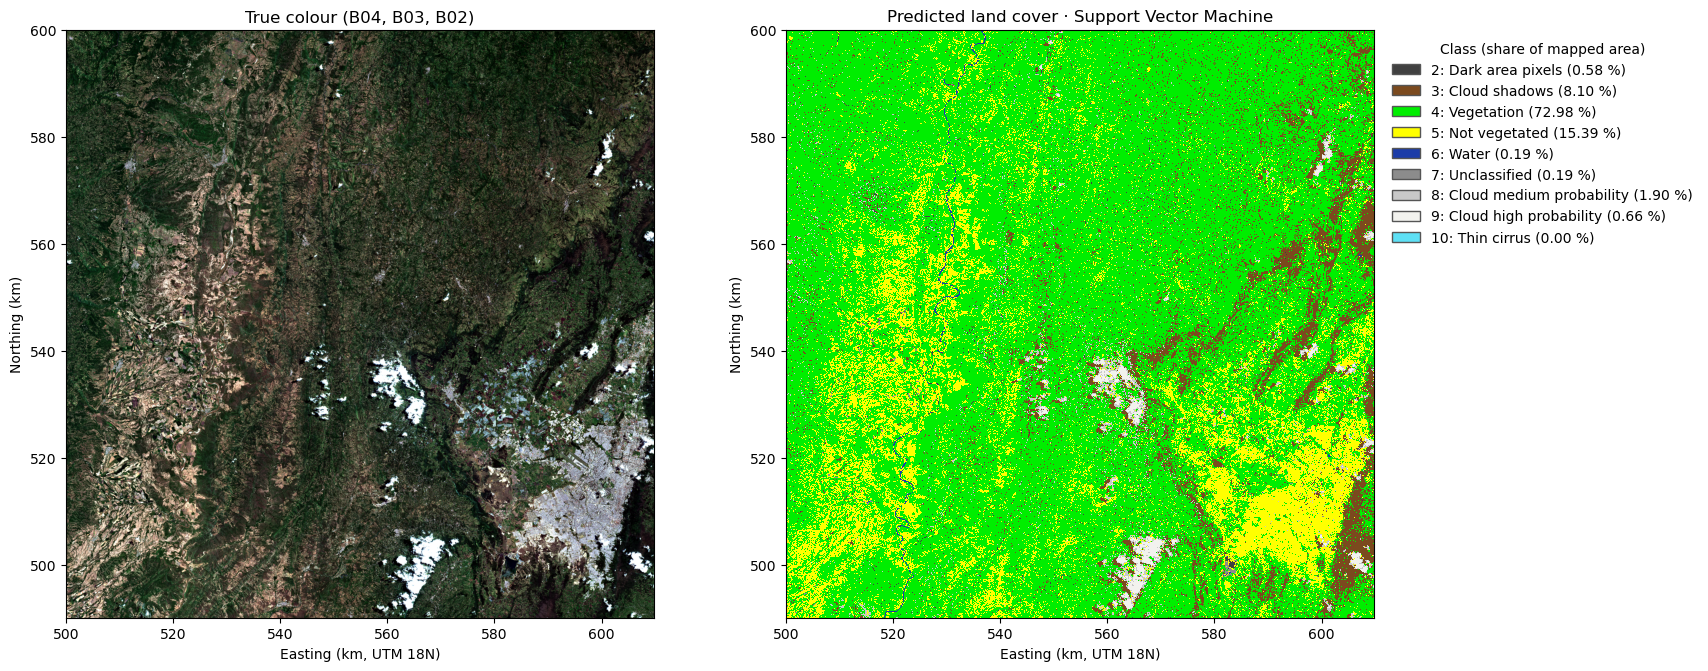

In [9]:
def true_colour(stack, step):
    # B04, B03, B02 stretched between the 2nd and 98th percentiles of the valid pixels.
    rgb = np.stack([stack[BANDS.index(b), ::step, ::step] for b in ("B04", "B03", "B02")], axis=-1).astype(float)
    mask = valid[::step, ::step]
    low, high = np.percentile(rgb[mask], [2, 98], axis=0)
    return np.clip((rgb - low) / (high - low), 0, 1)


step = 2  # 40 m display resolution; the GeoTIFF keeps 20 m
colormap = ListedColormap([CLASS_COLORS[code] for code in range(12)])
shown = np.ma.masked_equal(prediction[::step, ::step], NODATA_CODE)
extent = rasterio.transform.array_bounds(grid["height"], grid["width"], grid["transform"])
extent = (extent[0] / 1e3, extent[2] / 1e3, extent[1] / 1e3, extent[3] / 1e3)  # km, (left, right, bottom, top)

figure, (left, right) = plt.subplots(1, 2, figsize=(17, 6.6), constrained_layout=True)
left.imshow(true_colour(stack, step), extent=extent)
left.set_title("True colour (B04, B03, B02)")
right.imshow(shown, cmap=colormap, vmin=-0.5, vmax=11.5, interpolation="nearest", extent=extent)
right.set_title(f"Predicted land cover · {selected['model']}")
for axis in (left, right):
    axis.set(xlabel="Easting (km, UTM 18N)", ylabel="Northing (km)")
right.legend(handles=[Patch(facecolor=CLASS_COLORS[r.class_id], edgecolor="#555555",
                            label=f"{r.class_id}: {r.name} ({r.share_pct:.2f} %)") for r in areas.itertuples()],
             loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False, title="Class (share of mapped area)")
figure.savefig(OUTPUTS / "land_cover_map.png", dpi=170)
plt.show()

# Map alone, as in Figure 3 of the brief.
figure, axis = plt.subplots(figsize=(10, 8.4), constrained_layout=True)
axis.imshow(shown, cmap=colormap, vmin=-0.5, vmax=11.5, interpolation="nearest", extent=extent)
axis.set(title="Thematic land-cover map of Bogotá (T18NWL, 2026-08-10)",
         xlabel="Easting (km, UTM 18N)", ylabel="Northing (km)")
axis.legend(handles=[Patch(facecolor=CLASS_COLORS[r.class_id], edgecolor="#555555", label=f"{r.class_id}: {r.name}")
                     for r in areas.itertuples()], loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False,
            title="Land cover")
figure.savefig(OUTPUTS / "land_cover_map_only.png", dpi=170)
plt.close(figure)

## 9. Summary

In [10]:
summary = {
    "dataset": DATASET, "model": selected["model"], "model_key": selected["key"],
    "selected_from_run": selected["mlflow_run_id"], "final_run": final_run_id,
    "registered_model": f"{MODEL_NAME} v{version} @{MODEL_ALIAS}", "fit_pixels": int(len(y_all)),
    "fit_seconds": round(fit_seconds, 1), "predict_seconds": round(predict_seconds, 1),
    "raster": {"file": raster_name, "s3": f"s3://{DATA_BUCKET}/{prediction_key}", "crs": str(grid["crs"]),
               "transform": list(grid["transform"])[:6], "width": grid["width"], "height": grid["height"],
               "dtype": "uint8", "nodata": NODATA_CODE, "codes": codes},
    "mapped_pixels": mapped, "nodata_pixels": nodata_pixels,
    "mapped_area_km2": mapped * pixel_area_m2 / 1e6,
    "holdout_metrics_of_selected_configuration": {k: v for k, v in selected.items() if k.startswith("test_")},
}
(OUTPUTS / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
summary

{'dataset': 'T18NWL_20260810T152649',
 'model': 'Support Vector Machine',
 'model_key': 'svm',
 'selected_from_run': '58cfe1ee9a93410fb4f52e0f34264c6f',
 'final_run': '30916545c37e4440b33c84e190ebf243',
 'registered_model': 'sentinel2-land-cover v1 @production',
 'fit_pixels': 583835,
 'fit_seconds': 4260.7,
 'predict_seconds': 8578.0,
 'raster': {'file': 'T18NWL_20260810T152649_landcover_svm_v1.tif',
  's3': 's3://sentinel2/predictions/T18NWL_20260810T152649_landcover_svm_v1.tif',
  'crs': 'EPSG:32618',
  'transform': [20.0, 0.0, 499980.0, 0.0, -20.0, 600000.0],
  'width': 5490,
  'height': 5490,
  'dtype': 'uint8',
  'nodata': 255,
  'codes': [2, 3, 4, 5, 6, 7, 8, 9, 10, 255]},
 'mapped_pixels': 30140099,
 'nodata_pixels': 1,
 'mapped_area_km2': 12056.0396,
 'holdout_metrics_of_selected_configuration': {'test_overall_accuracy': 0.9356442540445467,
  'test_kappa': 0.849162602634695,
  'test_balanced_accuracy': 0.6608222762127729,
  'test_precision_macro': 0.7169966311024526,
  'test_r